# Re-select the scoring settings for the layer-32 predictors, on synthetic validation data only (plan item 8 follow-up)

**Why this notebook exists.** Notebook 11 trained predictors on layer-32 encoder tokens and scored them with the notebook 06 settings *carried over unchanged* (per-position z-score, `k = 3`, ...). Those settings were chosen for the **final-layer** predictor. Nothing says they are the best settings for layer 32. This notebook repeats the notebook 06 selection with the layer-32 predictors and the layer-32 synthetic/nominal caches, and stops after saving the choice.

**The test split is not used anywhere in this notebook.** Not read, not scored, not used for choosing. Concretely:

* only `MVTecADDataset(..., 'train')` is constructed (notebooks 06 and 11 call `validate_category_splits`, which also scans and hashes the test images; that call is deliberately avoided here);
* the only caches opened are `latents_layer32` (train and val), `layer_features/layer32` (val and synthetic) and the predictor checkpoints; no `*_test` path is touched (asserted below);
* no test result is consulted: notebook 06's *proxy-validity* section (Spearman against notebook 05 test numbers) and the 2x2-block capsule check are **not** repeated. The only saved record read is notebook 06's `selected_settings.json`, from which just the declared protocol and its final-layer choice are used (that file also holds a Spearman diagnostic against notebook 05 test numbers, which is ignored).

**Protocol: identical to notebook 06 (asserted against its saved record, not copied by hand).** Nothing is added to the candidate grid or removed from it.

1. **Cross-fitting**: 3 folds over the clean validation images; z-score, Mahalanobis and gate-quantile statistics for a held-out fold come from the other folds' clean images only.
2. **Greedy sequential selection** in the declared order: score family, smoothing `sigma`, image-score `k`, fusion `lambda`, gate `tau`; every option is scored with the earlier winners fixed.
3. **Criterion** `J`: mean over the three categories of mean(image AUROC at the stage's `k`, pixel AUROC, AUPRO).
4. **One global choice** for all categories. Options within `TIE_MARGIN = 0.005` of the best are tied; the earliest declared option (the simpler one) wins.

**What differs from notebook 06 (all forced by the layer-32 inputs, none changes the protocol)**

| | notebook 06 | this notebook |
| --- | --- | --- |
| predictors | `checkpoints/predictors` | `checkpoints/predictors_layer32` (identity = derived layer-32 hash) |
| clean validation / training tokens | `data/cache/latents` | `data/cache/latents_layer32` |
| synthetic tokens | `data/cache/synthetic_val/<fp>/<cat>.pt` (final layer) | `data/cache/layer_features/layer32/<cat>_synthetic.pt` (same synthetic images, layer 32) |
| split discovery | `validate_category_splits` (also scans test) | `MVTecADDataset(..., 'train')` only |
| storage precision | float32 | synthetic tokens are stored as float16; the clean validation tokens go through the same float16 store so both classes are treated alike (shown below to be exact and to change `1 - cos` by under 1e-6) |

## 1. Imports and configuration

In [1]:
import hashlib
import json
import os
import subprocess
import sys
import time
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from PIL import Image, ImageFilter

try:
    display
except NameError:
    display = print

candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next((p for p in candidates if (p / 'configs').is_dir() and (p / 'src').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

CATEGORIES = ('bottle', 'capsule', 'hazelnut')
LAYER = 32
ENCODER_CHECKPOINT = PROJECT_ROOT / 'checkpoints' / 'IN22K-vit.g.16-600e.pth.tar'
PREDICTOR_DIR = PROJECT_ROOT / 'checkpoints' / f'predictors_layer{LAYER}'
LAYER_LATENT_ROOT = PROJECT_ROOT / 'data' / 'cache' / f'latents_layer{LAYER}'          # train / val only
LAYER_FEATURE_ROOT = PROJECT_ROOT / 'data' / 'cache' / 'layer_features'               # val / synthetic only
SYNTHETIC_IMAGE_ROOT = PROJECT_ROOT / 'data' / 'synthetic_val'
SELECTION06 = PROJECT_ROOT / 'results' / 'improvements' / 'synthetic_val' / 'selected_settings.json'
OUTPUT_ROOT = Path(os.environ.get('LAYER32_SYNTHETIC_OUTPUT', PROJECT_ROOT / 'results' / 'improvements' / 'layer32_synthetic_val'))
FIGURE_ROOT = OUTPUT_ROOT / 'figures'
OVERWRITE = False
OUTPUT_FILES = ('settings_grid.csv', 'selected_settings.json', 'synthetic_set_summary.json', 'provenance_checks.json',
                'selected_vs_start.csv', 'carried_over_comparison.csv', 'gate_firing_diagnostic.csv')

MASKING_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'masking' / 'coarse_to_fine.yaml'
DATA_CONFIG = yaml.safe_load((PROJECT_ROOT / 'configs' / 'data' / 'mvtec.yaml').read_text(encoding='utf-8'))
VAL_FRACTION = float(DATA_CONFIG['nominal_split']['val_fraction'])
SPLIT_SEED = int(DATA_CONFIG['nominal_split']['seed'])
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- Declared by notebook 06, repeated verbatim (and asserted against its saved record below) ------
SYNTHETIC_SEED = 0
ANOMALIES_PER_IMAGE = 4
N_FOLDS = 3                                   # cross-fitting folds over the clean validation images
FAMILIES = (                                  # stage 1: per-token score; simplest first
    'baseline_cosine', 'pos_zscore', 'pos_centre', 'chan_standardise', 'layer_norm',
    'maha_d32', 'maha_d64', 'maha_d128',
)
SIGMAS = (0.0, 4.0, 8.0, 16.0)                # stage 2: smoothing sigma in px of the 224 map
K_VALUES = (1, 3, 5, 10, 20)                  # stage 3: image score = mean of the k highest tokens
LAMBDAS = (1.0, 0.0, 0.5, 2.0)                # stage 4: coarse + lambda * fine (default first)
TAU_OPTIONS = ('default', 'q0.9', 'q0.95', 'q0.99', 'q0.995')   # stage 5: fine-pass gate
TAU_QUANTILES = {'q0.9': 0.90, 'q0.95': 0.95, 'q0.99': 0.99, 'q0.995': 0.995}
START = {'family': 'baseline_cosine', 'sigma': 0.0, 'k': 5, 'lam': 1.0, 'tau': 'default'}
TIE_MARGIN = 0.005
POSITION_STD_FLOOR_FRACTION = 0.5
CHANNEL_STD_EPS = 1e-6
MAHA_RIDGE = 1e-3
CRITERION_TEXT = 'mean over categories of mean(image AUROC at the stage k, pixel AUROC, AUPRO)'
SELECTION_RULE_TEXT = 'greedy, in stage order family -> sigma -> k -> lambda -> tau; global across categories; earliest option within the tie margin'
# ----------------------------------------------------------------------------------------------------

# the protocol must be the one notebook 06 declared (only 'declared_before_results' and the final-layer choice are read)
saved06 = json.loads(SELECTION06.read_text(encoding='utf-8'))
declared06 = saved06['declared_before_results']
PROTOCOL = {'n_folds': N_FOLDS, 'families': list(FAMILIES), 'sigmas': list(SIGMAS), 'k_values': list(K_VALUES), 'lambdas': list(LAMBDAS),
        'tau_options': list(TAU_OPTIONS), 'start': START, 'tie_margin': TIE_MARGIN, 'criterion': CRITERION_TEXT, 'selection': SELECTION_RULE_TEXT,
        'position_std_floor_fraction': POSITION_STD_FLOOR_FRACTION, 'maha_ridge': MAHA_RIDGE}
mismatch = sorted(k for k in declared06 if declared06[k] != PROTOCOL.get(k))
if mismatch or saved06['test_used_for_selection'] is not False:
    raise ValueError(f'protocol differs from notebook 06 in {mismatch}, or notebook 06 reports test use')
FINAL_LAYER_SELECTION = saved06['selected_settings']
print('protocol identical to notebook 06 (declared_before_results):', sorted(declared06))
print('final-layer selection of notebook 06, for reference only:', FINAL_LAYER_SELECTION)

if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()]
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)) + ' (set OVERWRITE = True)')
print(f'Project: {PROJECT_ROOT}\nDevice: {DEVICE}\nOutputs: {OUTPUT_ROOT}')

protocol identical to notebook 06 (declared_before_results): ['criterion', 'families', 'k_values', 'lambdas', 'maha_ridge', 'n_folds', 'position_std_floor_fraction', 'selection', 'sigmas', 'start', 'tau_options', 'tie_margin']
final-layer selection of notebook 06, for reference only: {'family': 'pos_zscore', 'k': 3, 'lam': 1.0, 'sigma': 0.0, 'tau': 'default'}
Project: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD
Device: cuda
Outputs: C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\results\improvements\layer32_synthetic_val


## 2. Provenance, alignment and data

Everything below must hold or the notebook stops:

* the layer-32 **identity** (`SHA-256(checkpoint | layer=32 | token_layer_norm | v1)`) is the one recorded inside each predictor checkpoint and each latent cache (the loaders raise otherwise, and a layer-32 predictor is refused for the real checkpoint hash);
* each predictor was trained on exactly the train ids and validated on exactly the validation ids used here (so category alignment is per-category, by image content hash);
* the clean validation tokens from `latents_layer32` equal the `layer_features/layer32` validation tokens bit for bit after float16 rounding, which shows both stores come from one extraction pipeline;
* the synthetic tokens are loaded with the content hashes of the synthetic PNGs (verified against the manifest on load), the encoder checkpoint SHA-256, the preprocessing spec and the layer number;
* synthetic base images are exactly the validation images, and every defect mask survives reduction to 224 px.

In [2]:
from ijepa_ad.caching.latent_cache import compute_file_sha256
from ijepa_ad.caching.synthetic_cache import load_synthetic_manifest
from ijepa_ad.caching.cache_schema import CacheExpectations, PreprocessingSpec
from ijepa_ad.data.mvtec_dataset import MVTecADDataset
from ijepa_ad.data.splits import split_nominal_train_val
from ijepa_ad.data.synthetic_anomalies import SyntheticConfig
from ijepa_ad.data.transforms import PreprocessConfig
from ijepa_ad.encoder.layer_features import load_layer_features
from ijepa_ad.evaluation.metrics import aupro, image_auroc, pixel_auroc
from ijepa_ad.evaluation.runner import EMBEDDING_DIM, ENCODER_NAME, NUM_TOKENS, PATCH_SIZE
from ijepa_ad.inference import MaskedLatentScorer, load_masking_settings, load_predictor_checkpoint_with_provenance
from ijepa_ad.masking.score_maps import smooth_score_maps, upsample_patch_scores
from ijepa_ad.predictor.cache_dataset import load_cached_latent_dataset
from ijepa_ad.scoring import (
    ChannelStandardisedCosine, PositionNormaliser, cosine_discrepancy, fit_channel_stats,
    fit_mahalanobis_residual, layer_norm_cosine_discrepancy,
)

ENCODER_SHA256 = compute_file_sha256(ENCODER_CHECKPOINT)
LAYER_IDENTITY = hashlib.sha256(f'{ENCODER_SHA256}|layer={LAYER}|token_layer_norm|v1'.encode()).hexdigest()
LAYER_ENCODER_NAME = f'{ENCODER_NAME}_layer{LAYER}'
MASKING_SETTINGS = load_masking_settings(MASKING_CONFIG_PATH)
DEFAULT_TAU = MASKING_SETTINGS['threshold']
SYNTH_CONFIG = SyntheticConfig(seed=SYNTHETIC_SEED, anomalies_per_image=ANOMALIES_PER_IMAGE)
PREPROCESSING = PreprocessConfig(image_size=int(DATA_CONFIG['preprocessing']['image_size']))
PREPROCESSING_SPEC = PreprocessingSpec.from_config(PREPROCESSING)
print('synthetic fingerprint:', SYNTH_CONFIG.fingerprint())
print('encoder checkpoint sha256:', ENCODER_SHA256)
print('layer-32 identity:       ', LAYER_IDENTITY)

REQUESTED_PATHS = []          # every data file this notebook asks for; none may belong to the test split


def request(path):
    REQUESTED_PATHS.append(Path(path))
    return path


def expectations(category, split, samples):
    return CacheExpectations(
        category=category, split=split, encoder_name=LAYER_ENCODER_NAME, checkpoint_sha256=LAYER_IDENTITY,
        patch_size=PATCH_SIZE, embedding_dim=EMBEDDING_DIM, preprocessing=PREPROCESSING_SPEC,
        sample_ids=tuple(s.image_id for s in samples), num_tokens=NUM_TOKENS,
    )


def mask_at_224(path):
    mask = Image.open(path).convert('L').resize((224, 224), Image.Resampling.BOX)
    return np.asarray(mask) >= 128


def ids_digest(ids):
    return hashlib.sha256(json.dumps(list(ids)).encode()).hexdigest()


DATA, PREDICTORS, PROVENANCE = {}, {}, {}
for category in CATEGORIES:
    root = next(r for r in (PROJECT_ROOT / DATA_CONFIG['root'], PROJECT_ROOT / 'dataset', PROJECT_ROOT / 'dataset' / category)
                if (r / category / 'train').is_dir())
    train_ds = MVTecADDataset(root, category, 'train')                  # the official test split is neither listed nor read
    nominal = split_nominal_train_val(
        train_ds.samples, val_fraction=VAL_FRACTION, seed=SPLIT_SEED,
        min_train=int(DATA_CONFIG['nominal_split']['min_train']), min_val=int(DATA_CONFIG['nominal_split']['min_val']),
    )
    train_ids, val_ids_ordered = [s.image_id for s in nominal.train], [s.image_id for s in nominal.val]

    request(LAYER_LATENT_ROOT / category / 'val.pt'); request(LAYER_LATENT_ROOT / category / 'train.pt')
    val = load_cached_latent_dataset(LAYER_LATENT_ROOT, expectations(category, 'val', nominal.val), samples=train_ds.samples)
    train = load_cached_latent_dataset(LAYER_LATENT_ROOT, expectations(category, 'train', nominal.train), samples=train_ds.samples)
    if list(val.sample_ids) != val_ids_ordered or list(train.sample_ids) != train_ids:
        raise ValueError(f'{category}: layer-32 cache order differs from the nominal split')

    samples = load_synthetic_manifest(SYNTHETIC_IMAGE_ROOT, SYNTH_CONFIG, category)
    synth_ids = [s.image_id for s in samples]
    request(LAYER_FEATURE_ROOT / f'layer{LAYER:02d}' / f'{category}_val.pt'); request(LAYER_FEATURE_ROOT / f'layer{LAYER:02d}' / f'{category}_synthetic.pt')
    layer_val = load_layer_features(LAYER_FEATURE_ROOT, layer=LAYER, category=category, split='val', sample_ids=val_ids_ordered,
                                    checkpoint_sha256=ENCODER_SHA256, preprocessing=asdict(PREPROCESSING_SPEC))
    layer_synth = load_layer_features(LAYER_FEATURE_ROOT, layer=LAYER, category=category, split='synthetic', sample_ids=synth_ids,
                                      checkpoint_sha256=ENCODER_SHA256, preprocessing=asdict(PREPROCESSING_SPEC))
    if not torch.equal(val.latents.half(), layer_val.features):
        raise ValueError(f'{category}: latents_layer32 val differs from layer_features layer32 val')
    # float16 storage effect on the score: 1 - cos between the float32 tokens and their float16 round trip
    cos_gap = (1 - torch.nn.functional.cosine_similarity(val.latents.float(), layer_val.features.float(), dim=-1)).abs().max().item()
    if cos_gap > 1e-6:
        raise ValueError(f'{category}: float16 storage changes 1 - cos by {cos_gap:.2e}')
    if {s.base_image_id for s in samples} != set(val.sample_ids):
        raise ValueError(f'{category}: synthetic bases are not exactly the validation images')

    val_sorted = sorted(val_ids_ordered)
    fold_of = {image_id: rank % N_FOLDS for rank, image_id in enumerate(val_sorted)}
    masks_synth = np.stack([mask_at_224(s.mask_path) for s in samples])
    if not masks_synth.reshape(len(samples), -1).any(axis=1).all():
        raise ValueError(f'{category}: a synthetic mask vanished at 224 px')
    n_clean, n_synth = len(val), len(samples)
    clean_latents = layer_val.features.float()              # clean and synthetic tokens share one float16 store
    DATA[category] = {
        'latents': torch.cat([clean_latents, layer_synth.features.float()]),
        'labels': np.r_[np.zeros(n_clean, dtype=int), np.ones(n_synth, dtype=int)],
        'masks': np.concatenate([np.zeros((n_clean, 224, 224), dtype=bool), masks_synth]),
        'fold': np.r_[[fold_of[i] for i in val_ids_ordered], [fold_of[s.base_image_id] for s in samples]].astype(int),
        'n_clean': n_clean, 'train_latents': train.latents.float(), 'samples': samples,
    }

    predictor_path = request(PREDICTOR_DIR / f'{category}_cosine.pt')
    PREDICTORS[category], predictor_meta = load_predictor_checkpoint_with_provenance(
        predictor_path, category=category, encoder_sha256=LAYER_IDENTITY, device=DEVICE)
    payload = torch.load(predictor_path, map_location='cpu', weights_only=True)
    recorded = payload['cache_provenance']
    if (recorded['category'], recorded['encoder_name'], recorded['checkpoint_sha256']) != (category, LAYER_ENCODER_NAME, LAYER_IDENTITY):
        raise ValueError(f'{category}: predictor provenance is not the layer-32 identity')
    if list(recorded['val']['sample_ids']) != val_ids_ordered or list(recorded['train']['sample_ids']) != train_ids:
        raise ValueError(f'{category}: predictor train/val ids differ from the nominal split used here')
    try:
        load_predictor_checkpoint_with_provenance(predictor_path, category=category, encoder_sha256=ENCODER_SHA256, device='cpu')
        raise AssertionError('layer-32 predictor accepted the final-layer encoder hash')
    except ValueError as error:
        assert 'different encoder' in str(error), error

    folds = np.bincount(DATA[category]['fold'][:n_clean], minlength=N_FOLDS)
    PROVENANCE[category] = {
        'n_train_latents': len(train), 'n_clean_val': n_clean, 'n_synthetic': n_synth, 'clean_val_per_fold': folds.tolist(),
        'train_ids_sha256': ids_digest(train_ids), 'val_ids_sha256': ids_digest(val_ids_ordered), 'synthetic_ids_sha256': ids_digest(synth_ids),
        'predictor_file': str(predictor_path.relative_to(PROJECT_ROOT)), 'predictor_sha256': compute_file_sha256(predictor_path),
        'predictor_status': predictor_meta['status'], 'predictor_mask_strategy': predictor_meta['mask_strategy'],
        'predictor_training_config': {k: payload['training_config'][k] for k in ('mask_strategy', 'block_size', 'learning_rate', 'seed') if k in payload['training_config']},
        'predictor_best_epoch': payload.get('best_epoch'),
        'files_sha256': {str(p.relative_to(PROJECT_ROOT)): compute_file_sha256(p) for p in (
            LAYER_LATENT_ROOT / category / 'train.pt', LAYER_LATENT_ROOT / category / 'val.pt',
            LAYER_FEATURE_ROOT / f'layer{LAYER:02d}' / f'{category}_val.pt', LAYER_FEATURE_ROOT / f'layer{LAYER:02d}' / f'{category}_synthetic.pt')},
        'latents_layer32_val_equals_layer_features_val_after_fp16': True, 'max_abs_one_minus_cos_fp32_vs_fp16_val': cos_gap,
    }
    print(f'{category}: clean val={n_clean} (folds {folds.tolist()}), synthetic={n_synth}, train={len(train)}, '
          f'predictor={predictor_meta["status"]}/{predictor_meta["mask_strategy"]}, fp16 effect on 1-cos <= {cos_gap:.1e}')

leaked = [str(p) for p in REQUESTED_PATHS if 'test' in {part.lower().replace('.pt', '') for part in p.parts} or p.name.lower().startswith('test')
          or any(part.lower().endswith('_test') for part in p.parts)]
assert not leaked, f'a test-split path was requested: {leaked}'
print(f'{len(REQUESTED_PATHS)} data files requested, none belongs to the test split')

synthetic fingerprint: 46c947cb99e1faf4
encoder checkpoint sha256: a373c7b16165092e29bd5714c6ce79c574c4a52b01b64bf4c82dc81e6a82cf0b
layer-32 identity:        d1eade00ea52807522beb310587150ffa4cdb97a0140aa68a3dbb869954c4dd8
bottle: clean val=21 (folds [7, 7, 7]), synthetic=84, train=188, predictor=complete/inference_aligned, fp16 effect on 1-cos <= 3.6e-07
capsule: clean val=22 (folds [8, 7, 7]), synthetic=88, train=197, predictor=complete/inference_aligned, fp16 effect on 1-cos <= 3.6e-07
hazelnut: clean val=39 (folds [13, 13, 13]), synthetic=156, train=352, predictor=complete/inference_aligned, fp16 effect on 1-cos <= 3.6e-07
15 data files requested, none belongs to the test split


### Synthetic set summary

The synthetic images are the ones notebook 06 used (same fingerprint, same PNGs); only the encoder layer differs. One example per kind and category, defect outlined in red.

n  median_area_pct  min_area_pct  max_area_pct  \
category kind                                                        
bottle   cutpaste  42             0.99          0.28          3.67   
         perlin    42             1.21          0.30          3.96   
capsule  cutpaste  44             1.11          0.18          3.81   
         perlin    44             1.11          0.30          3.87   
hazelnut cutpaste  78             0.94          0.30          3.72   
         perlin    78             1.02          0.30          3.88   

                   mean_attempts  fallback  
category kind                               
bottle   cutpaste           1.05         0  
         perlin             1.19         0  
capsule  cutpaste           1.07         0  
         perlin             1.07         0  
hazelnut cutpaste           1.12         0  
         perlin             1.08         0

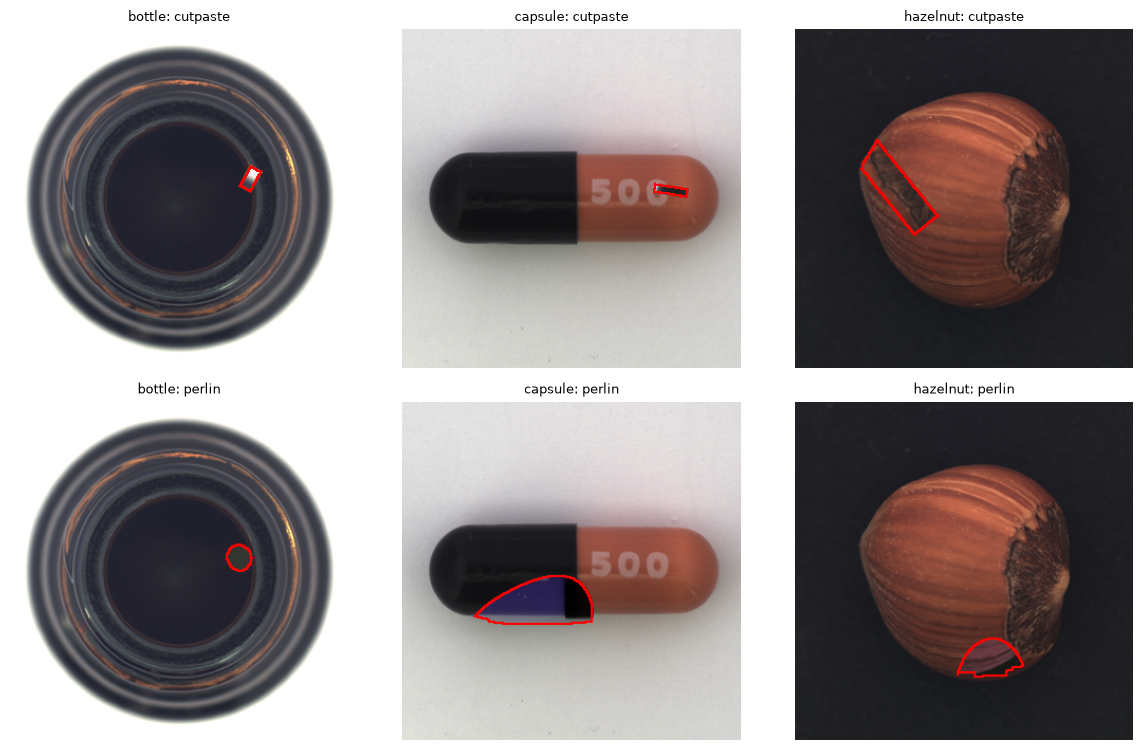

In [3]:
rows = []
for category in CATEGORIES:
    for s in DATA[category]['samples']:
        rows.append({'category': category, 'kind': s.kind, 'area_fraction': s.area_fraction, 'attempts': s.details['attempts'], 'foreground_fallback': s.details['foreground_fallback']})
synth_df = pd.DataFrame(rows)
display(synth_df.groupby(['category', 'kind']).agg(
    n=('area_fraction', 'size'), median_area_pct=('area_fraction', lambda a: 100 * a.median()),
    min_area_pct=('area_fraction', lambda a: 100 * a.min()), max_area_pct=('area_fraction', lambda a: 100 * a.max()),
    mean_attempts=('attempts', 'mean'), fallback=('foreground_fallback', 'sum')).round(2))

fig, axes = plt.subplots(2, len(CATEGORIES), figsize=(4 * len(CATEGORIES), 7.6))
for col, category in enumerate(CATEGORIES):
    for row, kind in enumerate(('cutpaste', 'perlin')):
        sample = next(s for s in DATA[category]['samples'] if s.kind == kind and s.variant >= 2)
        image = np.asarray(Image.open(sample.image_path).convert('RGB').resize((320, 320))).copy()
        mask = np.asarray(Image.open(sample.mask_path).resize((320, 320), Image.Resampling.NEAREST)) > 0
        edge = mask & ~np.asarray(Image.fromarray(mask.astype(np.uint8) * 255).filter(ImageFilter.MinFilter(5))).astype(bool)
        image[edge] = (255, 0, 0)
        axes[row, col].imshow(image); axes[row, col].set_title(f'{category}: {kind}', fontsize=9); axes[row, col].axis('off')
fig.tight_layout()
plt.show()
EXAMPLE_FIG = fig

## 3. Masked predictions, computed once

For every image (clean validation images, then their synthetic defect versions) the **layer-32** predictor is run with the coarse (4x4) windows and with the dense single-token windows. Everything that follows (every score family, `tau`, `lambda`, `sigma`, `k`) is a function of these predictions. The check below confirms that the post-hoc adaptive score equals what `MaskedLatentScorer` returns for the layer-32 predictor.

In [4]:
def masked_predictions(predictor, latents, coarse_size, dense=False):
    # dense=True: single-token (1x1) windows; the coarse size is then irrelevant
    settings = {**MASKING_SETTINGS, 'coarse_size': int(coarse_size)}
    scorer = MaskedLatentScorer(predictor, **settings)
    windows = scorer.fine.candidates() if dense else scorer.coarse.windows()
    out = torch.empty_like(latents)
    for i in range(len(latents)):
        out[i] = scorer.window_predictions(latents[i:i + 1].to(DEVICE), windows).cpu()
    return out, scorer


PRED = {}
for category in CATEGORIES:
    started = time.perf_counter()
    latents = DATA[category]['latents']
    coarse, scorer = masked_predictions(PREDICTORS[category], latents, MASKING_SETTINGS['coarse_size'])
    fine, _ = masked_predictions(PREDICTORS[category], latents, MASKING_SETTINGS['coarse_size'], dense=True)
    PRED[category] = {'coarse': coarse, 'fine': fine, 'scorer': scorer}
    print(f'{category}: {len(latents)} images, predictions in {time.perf_counter() - started:.0f}s')


def on_device(fn, predicted, actual, chunk=16):
    out = []
    for i in range(0, len(predicted), chunk):
        with torch.inference_mode():
            out.append(fn(predicted[i:i + chunk].to(DEVICE), actual[i:i + chunk].to(DEVICE)).cpu())
    return torch.cat(out)

C:\Users\aryan\OneDrive\Desktop\7 sem\I-JEPA-AD\.venv\Lib\site-packages\torch\nn\modules\transformer.py:685: UserWarning: 1Torch was not compiled with flash attention. (Triggered internally at ..\aten\src\ATen\native\transformers\cuda\sdp_utils.cpp:263.)
  return torch._transformer_encoder_layer_fwd(


bottle: 105 images, predictions in 27s
capsule: 110 images, predictions in 28s
hazelnut: 195 images, predictions in 49s


## 4. Score families, fitted by cross-fitting

Each family gives a coarse score and a dense fine score per token, for every image. Statistics are fitted per held-out fold from the clean images of the other folds (position z-score / centring, Mahalanobis, gate quantiles) or from the nominal **training** tokens of layer 32 (channel standardisation). The fine-pass gate is always evaluated on the baseline `1 - cos` region scores.

In [5]:
FAMILY_SCORES, REGION, TAU, BASE = {}, {}, {}, {}
for category in CATEGORIES:
    d = DATA[category]
    n, n_clean, fold = len(d['labels']), d['n_clean'], d['fold']
    A, Pc, Pf = d['latents'], PRED[category]['coarse'], PRED[category]['fine']
    scorer = PRED[category]['scorer']
    cos_c, cos_f = on_device(cosine_discrepancy, Pc, A), on_device(cosine_discrepancy, Pf, A)
    BASE[category] = (cos_c, cos_f)
    region = torch.zeros_like(cos_c)
    for window in scorer.coarse.windows():
        idx = list(window.token_indices)
        region[:, idx] = cos_c[:, idx].mean(dim=1, keepdim=True)
    REGION[category] = region

    chan = ChannelStandardisedCosine(fit_channel_stats(d['train_latents'], eps=CHANNEL_STD_EPS))
    families = {
        'baseline_cosine': (cos_c, cos_f),
        'chan_standardise': (on_device(chan, Pc, A), on_device(chan, Pf, A)),
        'layer_norm': (on_device(layer_norm_cosine_discrepancy, Pc, A), on_device(layer_norm_cosine_discrepancy, Pf, A)),
    }
    for name in ('pos_zscore', 'pos_centre') + tuple(f for f in FAMILIES if f.startswith('maha')):
        families[name] = (torch.zeros_like(cos_c), torch.zeros_like(cos_f))
    tau = {key: torch.zeros(n) for key in TAU_OPTIONS}
    tau['default'][:] = DEFAULT_TAU
    for f in range(N_FOLDS):
        fit = np.flatnonzero((fold != f) & (np.arange(n) < n_clean))     # clean images of the other folds
        held = np.flatnonzero(fold == f)                                  # this fold's clean + synthetic images
        for name, divide in (('pos_zscore', True), ('pos_centre', False)):
            kwargs = {'divide': divide, **({'std_floor_fraction': POSITION_STD_FLOOR_FRACTION} if divide else {})}
            norm_c, norm_f = PositionNormaliser.fit(cos_c[fit], **kwargs), PositionNormaliser.fit(cos_f[fit], **kwargs)
            families[name][0][held] = norm_c.apply(cos_c[held])
            families[name][1][held] = norm_f.apply(cos_f[held])
        residuals = (A[fit] - Pc[fit]).reshape(-1, A.shape[-1])
        for name in (f for f in FAMILIES if f.startswith('maha')):
            model = fit_mahalanobis_residual(residuals, n_components=int(name[6:]), ridge=MAHA_RIDGE)
            families[name][0][held] = on_device(model, Pc[held], A[held])
            families[name][1][held] = on_device(model, Pf[held], A[held])
        for key, q in TAU_QUANTILES.items():
            tau[key][held] = float(np.quantile(region[fit].flatten().numpy(), q))
    FAMILY_SCORES[category], TAU[category] = families, tau
    print(f'{category}: {len(families)} families fitted on {N_FOLDS} folds; example tau (fold 0) ' + ', '.join(f'{k}={tau[k][fold == 0][0]:.3f}' for k in TAU_OPTIONS))


def patch_scores(category, family, tau_key, lam):
    coarse, fine = FAMILY_SCORES[category][family]
    fired = REGION[category] >= TAU[category][tau_key][:, None]
    return coarse + lam * fired.float() * fine


# the post-hoc adaptive score must equal what the scorer returns for the baseline settings
for category in CATEGORIES:
    scorer = MaskedLatentScorer(PREDICTORS[category], **MASKING_SETTINGS)
    post_hoc = patch_scores(category, 'baseline_cosine', 'default', MASKING_SETTINGS['lam'])
    for i in (0, DATA[category]['n_clean'], len(post_hoc) - 1):
        reference = scorer.score(DATA[category]['latents'][i:i + 1].to(DEVICE), mode='adaptive').patch_scores.cpu()
        assert torch.allclose(post_hoc[i], reference, atol=1e-5), (category, i, (post_hoc[i] - reference).abs().max())
print('post-hoc adaptive scores equal MaskedLatentScorer for the baseline settings (layer-32 predictors)')

bottle: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.079, q0.95=0.086, q0.99=0.113, q0.995=0.125
capsule: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.171, q0.95=0.186, q0.99=0.207, q0.995=0.228
hazelnut: 8 families fitted on 3 folds; example tau (fold 0) default=0.500, q0.9=0.215, q0.95=0.229, q0.99=0.260, q0.995=0.261
post-hoc adaptive scores equal MaskedLatentScorer for the baseline settings (layer-32 predictors)


### Does the fine pass fire? (diagnostic, not part of the criterion)

The default gate `tau = 0.5` was set on final-layer scores. Whether it fires at all on layer-32 predictions decides how much `lambda` can matter, and the quantile gates change the work per image, so the fraction of tokens that fire is shown for every gate option. The selection does **not** use compute cost.

In [6]:
fire_rows = []
for category in CATEGORIES:
    n_clean = DATA[category]['n_clean']
    for key in TAU_OPTIONS:
        fired = (REGION[category] >= TAU[category][key][:, None]).float()
        fire_rows.append({'category': category, 'tau': key, 'mean_tau': float(TAU[category][key].mean()),
                          'fired_token_fraction_clean': float(fired[:n_clean].mean()), 'fired_token_fraction_synthetic': float(fired[n_clean:].mean()),
                          'images_with_any_fire_clean': float((fired[:n_clean].sum(1) > 0).float().mean()),
                          'images_with_any_fire_synthetic': float((fired[n_clean:].sum(1) > 0).float().mean())})
fire_df = pd.DataFrame(fire_rows)
display(fire_df.round(4))

,category,tau,mean_tau,fired_token_fraction_clean,fired_token_fraction_synthetic,images_with_any_fire_clean,images_with_any_fire_synthetic
0,bottle,default,0.5000,0.0000,0.0010,0.0000,0.0119
1,bottle,q0.9,0.0808,0.1011,0.3207,0.5714,0.9643
2,bottle,q0.95,0.0884,0.0603,0.2522,0.4762,0.9405
3,bottle,q0.99,0.1154,0.0136,0.1283,0.1905,0.8214
4,bottle,q0.995,0.1345,0.0058,0.0923,0.1429,0.7500
5,capsule,default,0.5000,0.0000,0.0000,0.0000,0.0000
6,capsule,q0.9,0.1712,0.1030,0.1865,1.0000,1.0000
7,capsule,q0.95,0.1933,0.0538,0.1171,0.5909,0.7955
8,capsule,q0.99,0.2231,0.0204,0.0635,0.2727,0.5909
9,capsule,q0.995,0.2328,0.0093,0.0459,0.1818,0.5227


## 5. Evaluation function

For a configuration `(family, tau, lambda, sigma)` the function returns image AUROC for every `k`, pixel AUROC and AUPRO (same implementations and settings as the test evaluation). Pixel metrics are measured at 224 x 224 against the defect masks reduced to that size. Clean images contribute empty masks. Smoothed configurations read the image score at the 196 token centres.

In [7]:
def centre_samples(maps224):
    return torch.nn.functional.avg_pool2d(maps224[:, :, 7:, 7:], kernel_size=2, stride=16).flatten(1)


CACHE = {}


def evaluate(category, family, tau_key, lam, sigma):
    key = (category, family, tau_key, lam, sigma)
    if key in CACHE:
        return CACHE[key]
    labels, masks = DATA[category]['labels'], list(DATA[category]['masks'])
    patch = patch_scores(category, family, tau_key, lam)
    if sigma == 0.0:
        token_scores = patch
        maps = upsample_patch_scores(patch, output_size=224)[:, 0].numpy()
    else:
        smoothed = smooth_score_maps(upsample_patch_scores(patch, output_size=224), sigma)
        token_scores = centre_samples(smoothed)
        maps = smoothed[:, 0].numpy()
    maps = list(maps.astype(np.float32))
    result = {f'image_auroc_k{k}': image_auroc(labels, token_scores.topk(k, dim=1).values.mean(dim=1).numpy()) for k in K_VALUES}
    result['pixel_auroc'] = pixel_auroc(maps, masks)
    result['aupro'] = aupro(maps, masks, num_thresholds=200)
    CACHE[key] = result
    return result


def criterion(result, k):
    return (result[f'image_auroc_k{k}'] + result['pixel_auroc'] + result['aupro']) / 3


started = time.perf_counter()
reference = {c: evaluate(c, 'baseline_cosine', 'default', 1.0, 0.0) for c in CATEGORIES}
print(f'one evaluation per category took {time.perf_counter() - started:.1f}s')
display(pd.DataFrame(reference).T.round(3))

one evaluation per category took 4.3s


,image_auroc_k1,image_auroc_k3,image_auroc_k5,image_auroc_k10,image_auroc_k20,pixel_auroc,aupro
bottle,0.908,0.922,0.923,0.920,0.910,0.984,0.929
capsule,0.780,0.842,0.844,0.854,0.853,0.975,0.917
hazelnut,0.857,0.904,0.909,0.904,0.898,0.984,0.924


**How hard is the proxy for the layer-32 predictors?** The baseline row above is the starting configuration (layer-32 predictor, `1 - cos`, adaptive, default `tau`) on the synthetic set. If image AUROC were about 1.0 for every category there would be no room to tell settings apart (a ceiling), and near 0.5 the defects would not be detectable. A ceiling would limit how much the tie rule can resolve and is reported as a limitation.

## 6. Greedy sequential selection

Stages run in the declared order. For each stage every option is evaluated with the earlier winners fixed, `J` is averaged over the three categories, and the earliest option within `TIE_MARGIN` of the best wins. All evaluations are saved, not just the winners, and the options inside the margin are listed so close alternatives are visible.


stage family: selected 'maha_d128'  (J_mean 0.9615, best 0.9615); per-category best: {'bottle': 'maha_d128', 'capsule': 'pos_zscore', 'hazelnut': 'pos_zscore'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected,within_tie_margin
0,family,baseline_cosine,0.9457,0.9121,0.9387,0.9322,False,False
1,family,pos_zscore,0.9339,0.9740,0.9489,0.9523,False,False
2,family,pos_centre,0.9455,0.9539,0.9436,0.9477,False,False
3,family,chan_standardise,0.9283,0.7581,0.8352,0.8405,False,False
4,family,layer_norm,0.9457,0.9121,0.9387,0.9322,False,False
5,family,maha_d32,0.9346,0.8298,0.8369,0.8671,False,False
6,family,maha_d64,0.9537,0.9040,0.9073,0.9217,False,False
7,family,maha_d128,0.9673,0.9689,0.9483,0.9615,True,True



stage sigma: selected 0.0  (J_mean 0.9615, best 0.9615); per-category best: {'bottle': '4.0', 'capsule': '0.0', 'hazelnut': '0.0'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected,within_tie_margin
0,sigma,0.0,0.9673,0.9689,0.9483,0.9615,True,True
1,sigma,4.0,0.9688,0.9680,0.9469,0.9613,False,True
2,sigma,8.0,0.9668,0.9668,0.9426,0.9587,False,True
3,sigma,16.0,0.9513,0.9498,0.9110,0.9374,False,False



stage k: selected 1  (J_mean 0.9610, best 0.9626); per-category best: {'bottle': '5', 'capsule': '3', 'hazelnut': '1'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected,within_tie_margin
0,k,1,0.9670,0.9631,0.9531,0.9610,True,True
1,k,3,0.9668,0.9689,0.9520,0.9626,False,True
2,k,5,0.9673,0.9689,0.9483,0.9615,False,True
3,k,10,0.9658,0.9665,0.9411,0.9578,False,True
4,k,20,0.9645,0.9600,0.9316,0.9520,False,False



stage lam: selected 1.0  (J_mean 0.9610, best 0.9612); per-category best: {'bottle': '0.0', 'capsule': '1.0', 'hazelnut': '1.0'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected,within_tie_margin
0,lam,1.0,0.9670,0.9631,0.9531,0.9610,True,True
1,lam,0.0,0.9674,0.9631,0.9531,0.9612,False,True
2,lam,0.5,0.9671,0.9631,0.9531,0.9611,False,True
3,lam,2.0,0.9662,0.9631,0.9531,0.9608,False,True



stage tau: selected 'default'  (J_mean 0.9610, best 0.9610); per-category best: {'bottle': 'default', 'capsule': 'default', 'hazelnut': 'default'}


,stage,option,J_bottle,J_capsule,J_hazelnut,J_mean,selected,within_tie_margin
0,tau,default,0.9670,0.9631,0.9531,0.9610,True,True
1,tau,q0.9,0.9557,0.9250,0.9244,0.9350,False,False
2,tau,q0.95,0.9535,0.9344,0.9314,0.9398,False,False
3,tau,q0.99,0.9530,0.9381,0.9380,0.9430,False,False
4,tau,q0.995,0.9544,0.9431,0.9370,0.9448,False,False



SELECTED SETTINGS (global, layer 32): {'family': 'maha_d128', 'sigma': 0.0, 'k': 1, 'lam': 1.0, 'tau': 'default'}


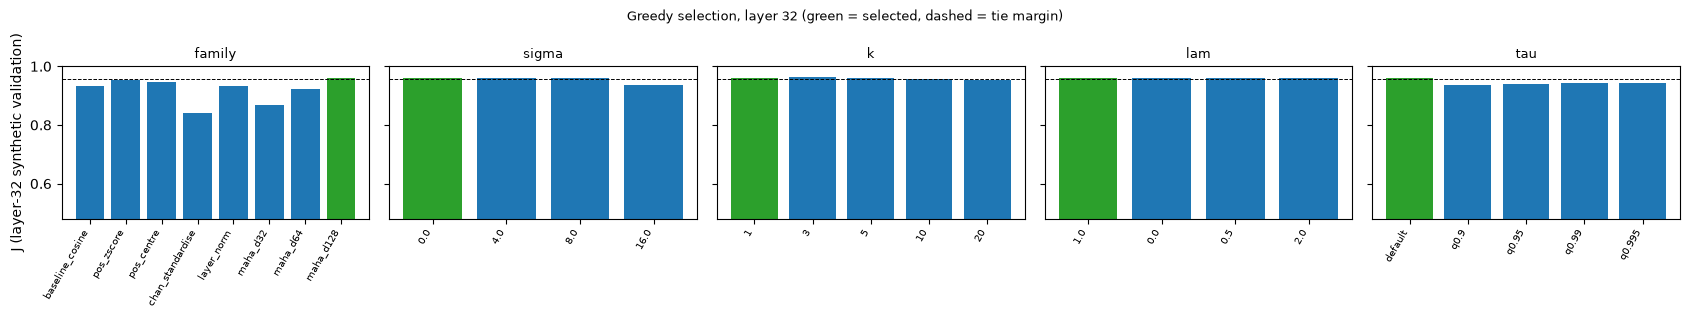

In [8]:
STAGES = (('family', FAMILIES), ('sigma', SIGMAS), ('k', K_VALUES), ('lam', LAMBDAS), ('tau', TAU_OPTIONS))
grid_rows, SELECTION = [], []
current = dict(START)
for stage, options in STAGES:
    stage_rows = []
    for option in options:
        setting = {**current, stage: option}
        row = {'stage': stage, 'option': str(option)}
        per_category = {}
        for category in CATEGORIES:
            result = evaluate(category, setting['family'], setting['tau'], setting['lam'], setting['sigma'])
            per_category[category] = criterion(result, setting['k'])
            grid_rows.append({
                'stage': stage, 'option': str(option), 'category': category, **{f'cfg_{k}': v for k, v in setting.items()},
                'image_auroc_at_cfg_k': result[f'image_auroc_k{setting["k"]}'], 'pixel_auroc': result['pixel_auroc'],
                'aupro': result['aupro'], 'J': per_category[category],
                **{f'image_auroc_k{k}': result[f'image_auroc_k{k}'] for k in K_VALUES},
            })
        row.update({f'J_{c}': v for c, v in per_category.items()})
        row['J_mean'] = float(np.mean(list(per_category.values())))
        stage_rows.append(row)
    table = pd.DataFrame(stage_rows)
    best = table.J_mean.max()
    winner_index = next(i for i, r in table.iterrows() if r.J_mean >= best - TIE_MARGIN)       # earliest within the margin
    winner = options[winner_index]
    table['selected'] = [i == winner_index for i in table.index]
    table['within_tie_margin'] = table.J_mean >= best - TIE_MARGIN
    per_category_best = {c: str(options[int(table[f'J_{c}'].idxmax())]) for c in CATEGORIES}
    SELECTION.append({'stage': stage, 'winner': winner if not isinstance(winner, np.generic) else winner.item(),
                      'J_mean_of_winner': float(table.J_mean[winner_index]), 'best_J_mean': float(best),
                      'best_option': str(options[int(table.J_mean.idxmax())]),
                      'tie_broken_toward_simpler': bool(table.J_mean[winner_index] < best), 'per_category_best_option': per_category_best,
                      'options_within_tie_margin': {str(options[i]): float(table.J_mean[i]) for i in table.index if table.within_tie_margin[i]},
                      'table': table.round(4).to_dict(orient='records')})
    current[stage] = winner
    print(f'\nstage {stage}: selected {winner!r}  (J_mean {table.J_mean[winner_index]:.4f}, best {best:.4f}); per-category best: {per_category_best}')
    display(table.round(4))
SELECTED = dict(current)
print('\nSELECTED SETTINGS (global, layer 32):', SELECTED)

fig, axes = plt.subplots(1, len(STAGES), figsize=(3.4 * len(STAGES), 3.2), sharey=True)
for ax, entry in zip(axes, SELECTION):
    labels_ = [r['option'] for r in entry['table']]
    values = [r['J_mean'] for r in entry['table']]
    colours = ['tab:green' if r['selected'] else 'tab:blue' for r in entry['table']]
    ax.bar(range(len(values)), values, color=colours)
    ax.axhline(entry['best_J_mean'] - TIE_MARGIN, color='black', linestyle='--', linewidth=0.7)
    ax.set_xticks(range(len(values))); ax.set_xticklabels(labels_, rotation=60, ha='right', fontsize=7)
    ax.set_title(entry['stage'], fontsize=9)
    ax.set_ylim(max(0.0, min(min(values), 0.5) - 0.02), 1.0)
axes[0].set_ylabel('J (layer-32 synthetic validation)')
fig.suptitle('Greedy selection, layer 32 (green = selected, dashed = tie margin)', fontsize=9)
fig.tight_layout()
plt.show()
STAGE_FIG = fig

### What the selection gained, on the data it was chosen on

The selected configuration against the starting configuration, per category. This is **optimistic** by construction (chosen on these very images); it only shows the size of the selected effect on the proxy. It is not evidence about the test split.

In [9]:
final_rows = []
for label, setting in (('start (baseline score)', START), ('selected (layer 32)', SELECTED)):
    for category in CATEGORIES:
        r = evaluate(category, setting['family'], setting['tau'], setting['lam'], setting['sigma'])
        final_rows.append({'config': label, 'category': category, f'image_auroc_k{setting["k"]}': r[f'image_auroc_k{setting["k"]}'],
                           'pixel_auroc': r['pixel_auroc'], 'aupro': r['aupro'], 'J': criterion(r, setting['k'])})
final_df = pd.DataFrame(final_rows)
display(final_df.round(4))

,config,category,image_auroc_k5,pixel_auroc,aupro,J,image_auroc_k1
0,start (baseline score),bottle,0.9235,0.9842,0.9294,0.9457,NaN
1,start (baseline score),capsule,0.8440,0.9751,0.9172,0.9121,NaN
2,start (baseline score),hazelnut,0.9086,0.9837,0.9237,0.9387,NaN
3,selected (layer 32),bottle,NaN,0.9887,0.9468,0.9670,0.9654
4,selected (layer 32),capsule,NaN,0.9928,0.9744,0.9631,0.9220
5,selected (layer 32),hazelnut,NaN,0.9869,0.9462,0.9531,0.9262


## 7. Save the selection

The selection record is written here, in one piece, with the declared grid, the criterion and tie rule, the stage tables, the data and cache provenance and an explicit statement that the test split was not used. The carried-over comparison in the next section is computed afterwards and cannot influence the choice.

In [10]:
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
if not OVERWRITE:
    existing = [OUTPUT_ROOT / n for n in OUTPUT_FILES if (OUTPUT_ROOT / n).exists()] + list(FIGURE_ROOT.glob('*.png'))
    if existing:
        raise FileExistsError('Refusing to overwrite: ' + ', '.join(map(str, existing)))


def git_state():
    def run(*args):
        try:
            return subprocess.run(['git', *args], cwd=PROJECT_ROOT, capture_output=True, text=True, check=False).stdout.strip()
        except OSError:
            return ''
    return {'head': run('rev-parse', 'HEAD') or 'unavailable', 'dirty_files': len(run('status', '--porcelain').splitlines())}


pd.DataFrame(grid_rows).to_csv(OUTPUT_ROOT / 'settings_grid.csv', index=False)
final_df.to_csv(OUTPUT_ROOT / 'selected_vs_start.csv', index=False)
fire_df.to_csv(OUTPUT_ROOT / 'gate_firing_diagnostic.csv', index=False)
EXAMPLE_FIG.savefig(FIGURE_ROOT / 'synthetic_examples.png', dpi=130, bbox_inches='tight')
STAGE_FIG.savefig(FIGURE_ROOT / 'stage_scores.png', dpi=140, bbox_inches='tight')

SYNTHETIC_SUMMARY = {
    'generator_fingerprint': SYNTH_CONFIG.fingerprint(), 'generator_config': {k: v for k, v in SYNTH_CONFIG.__dict__.items()},
    'same_synthetic_images_as_notebook_06': True,
    'base_images': 'nominal validation images only', 'texture_sources': 'nominal training images only',
    'test_split_used': False, 'encoder_sha256': ENCODER_SHA256, 'layer': LAYER, 'layer_identity': LAYER_IDENTITY,
    'counts': {c: {'clean_validation': int(DATA[c]['n_clean']), 'synthetic': int(len(DATA[c]['samples']))} for c in CATEGORIES},
    'by_kind': synth_df.groupby(['category', 'kind']).size().unstack().to_dict(orient='index'),
}
(OUTPUT_ROOT / 'synthetic_set_summary.json').write_text(json.dumps(SYNTHETIC_SUMMARY, indent=2, sort_keys=True, default=str), encoding='utf-8')

PROVENANCE_RECORD = {
    'layer': LAYER, 'encoder_name': LAYER_ENCODER_NAME, 'encoder_checkpoint_sha256': ENCODER_SHA256, 'layer_identity_sha256': LAYER_IDENTITY,
    'layer_identity_formula': 'SHA-256(checkpoint_sha256|layer=32|token_layer_norm|v1)',
    'predictors': 'checkpoints/predictors_layer32 (trained by scripts/train_predictor.py CLI defaults, one run per category; identity verified, train/val ids verified)',
    'clean_validation_and_training_tokens': 'data/cache/latents_layer32 (train.pt, val.pt)',
    'synthetic_tokens': 'data/cache/layer_features/layer32/<category>_synthetic.pt (float16; keyed by content hash of each synthetic PNG)',
    'clean_validation_tokens_used': 'data/cache/layer_features/layer32/<category>_val.pt (float16), bit-identical to latents_layer32 val after float16 rounding',
    'synthetic_fingerprint': SYNTH_CONFIG.fingerprint(),
    'requested_data_files': sorted(str(p.relative_to(PROJECT_ROOT)) for p in REQUESTED_PATHS),
    'per_category': PROVENANCE, 'git': git_state(), 'torch': torch.__version__, 'device': DEVICE,
    'checks_passed': [
        'predictor identity == latent cache identity == derived layer-32 hash', 'layer-32 predictor rejected for the final-layer encoder hash',
        'predictor train/val ids == nominal split ids used here', 'latents_layer32 val == layer_features layer32 val after float16 rounding',
        'synthetic PNG hashes verified against the manifest; layer features keyed by those hashes', 'synthetic base images == validation images',
        'every defect mask non-empty at 224 px', 'post-hoc adaptive scores == MaskedLatentScorer', 'no *test* path requested',
    ],
}
(OUTPUT_ROOT / 'provenance_checks.json').write_text(json.dumps(PROVENANCE_RECORD, indent=2, sort_keys=True, default=str), encoding='utf-8')

selected = {
    'declared_before_results': PROTOCOL,
    'protocol_identical_to_notebook_06': True,
    'selected_settings': SELECTED,
    'stages': SELECTION,
    'chosen_from': 'layer-32 synthetic-anomaly validation set (nominal validation images + fixed-seed synthetic defects), cross-fitted, layer-32 predictors',
    'criterion': CRITERION_TEXT,
    'tie_rule': f'options within {TIE_MARGIN} of the stage best are tied; the earliest option in the declared list wins',
    'candidate_grid': {'family': list(FAMILIES), 'sigma': list(SIGMAS), 'k': list(K_VALUES), 'lam': list(LAMBDAS), 'tau': list(TAU_OPTIONS),
                       'tau_quantiles': TAU_QUANTILES, 'start': START},
    'provenance': {'layer': LAYER, 'layer_identity_sha256': LAYER_IDENTITY, 'encoder_checkpoint_sha256': ENCODER_SHA256,
                   'synthetic_fingerprint': SYNTH_CONFIG.fingerprint(), 'predictors_dir': 'checkpoints/predictors_layer32',
                   'predictor_sha256': {c: PROVENANCE[c]['predictor_sha256'] for c in CATEGORIES},
                   'details_file': 'provenance_checks.json'},
    'test_used_for_selection': False,
    'test_split_read': False,
    'test_split_statement': 'The official MVTec test split was not read, listed, hashed, encoded, scored or otherwise used in this selection: only MVTecADDataset(train) was constructed, no *_test cache was opened, and no test result was used (the notebook 06 record was read for its declared protocol and final-layer choice only; its after-the-fact Spearman diagnostic against notebook 05 test numbers was ignored).',
    'not_applied_to_test': True,
    'not_covered': 'encoder layer (fixed at 32), mask block size; the 2x2-block capsule check and the proxy-validity check against test numbers are intentionally not repeated',
    'carried_over_from_notebook_06': FINAL_LAYER_SELECTION,
    'notebook': 'notebooks/12_layer32_synthetic_settings.ipynb',
}
(OUTPUT_ROOT / 'selected_settings.json').write_text(json.dumps(selected, indent=2, sort_keys=True, default=str), encoding='utf-8')
print('selection saved:', SELECTED)

selection saved: {'family': 'maha_d128', 'sigma': 0.0, 'k': 1, 'lam': 1.0, 'tau': 'default'}


## 8. Compared with the carried-over notebook 06 settings (diagnostic, after the selection was saved)

Notebook 11 scored the layer-32 predictors with the final-layer selection (`pos_zscore`, `sigma 0`, `k = 3`, `lambda 1`, default `tau`). Here that configuration and the starting configuration are scored with the same criterion on the layer-32 synthetic set, next to the new selection. All three are in or follow from the grid already evaluated, so this adds no choice. It is on the selection data, hence optimistic; it is not a test result.

In [11]:
compare = {'start (baseline score, k=5)': START, 'carried over from notebook 06': FINAL_LAYER_SELECTION, 'selected for layer 32': SELECTED}
cmp_rows = []
for label, setting in compare.items():
    row = {'config': label, **{k: setting[k] for k in ('family', 'sigma', 'k', 'lam', 'tau')}}
    js = []
    for category in CATEGORIES:
        r = evaluate(category, setting['family'], setting['tau'], setting['lam'], setting['sigma'])
        j = criterion(r, setting['k'])
        js.append(j)
        row.update({f'J_{category}': j, f'image_auroc_{category}': r[f'image_auroc_k{setting["k"]}'],
                    f'pixel_auroc_{category}': r['pixel_auroc'], f'aupro_{category}': r['aupro']})
    row['J_mean'] = float(np.mean(js))
    cmp_rows.append(row)
cmp_df = pd.DataFrame(cmp_rows)
display(cmp_df[['config', 'family', 'sigma', 'k', 'lam', 'tau', 'J_bottle', 'J_capsule', 'J_hazelnut', 'J_mean']].round(4))
cmp_df.to_csv(OUTPUT_ROOT / 'carried_over_comparison.csv', index=False)

saved = json.loads((OUTPUT_ROOT / 'selected_settings.json').read_text(encoding='utf-8'))
saved['diagnostic_after_selection'] = {
    'note': 'computed after the selection was saved; does not influence it',
    'J_mean': {r['config']: r['J_mean'] for r in cmp_rows},
    'carried_over_equals_selected': dict(FINAL_LAYER_SELECTION) == dict(SELECTED),
    'selected_beats_carried_over_by': float(cmp_df.J_mean.iloc[2] - cmp_df.J_mean.iloc[1]),
    'tie_margin': TIE_MARGIN,
}
(OUTPUT_ROOT / 'selected_settings.json').write_text(json.dumps(saved, indent=2, sort_keys=True, default=str), encoding='utf-8')
print(json.dumps(saved['diagnostic_after_selection'], indent=2))
print('final check: no test path requested ->', not any('test' in str(p).lower() for p in REQUESTED_PATHS))

,config,family,sigma,k,lam,tau,J_bottle,J_capsule,J_hazelnut,J_mean
0,"start (baseline score, k=5)",baseline_cosine,0.0,5,1.0,default,0.9457,0.9121,0.9387,0.9322
1,carried over from notebook 06,pos_zscore,0.0,3,1.0,default,0.9341,0.9709,0.9478,0.9509
2,selected for layer 32,maha_d128,0.0,1,1.0,default,0.9670,0.9631,0.9531,0.9610


{
  "note": "computed after the selection was saved; does not influence it",
  "J_mean": {
    "start (baseline score, k=5)": 0.9321626139797049,
    "carried over from notebook 06": 0.9509346108552518,
    "selected for layer 32": 0.9610404052931556
  },
  "carried_over_equals_selected": false,
  "selected_beats_carried_over_by": 0.010105794437903826,
  "tie_margin": 0.005
}
final check: no test path requested -> True


## What you can and cannot say

**You can say**

* The scoring settings for the layer-32 predictors were re-selected with the notebook 06 protocol (same grid, criterion, cross-fitting, tie rule, one global choice) using only nominal validation images and fixed-seed synthetic defects, without reading, scoring or consulting the official test split.
* Which settings were chosen, how close the alternatives were (`options_within_tie_margin` per stage), which category preferred what, and whether the choice differs from the one carried over from the final-layer predictor.
* Where the data came from: hashes of the predictors and caches, the layer-32 identity, the synthetic fingerprint (`provenance_checks.json`).

**You cannot say**

* That the selected settings improve the **test** split. That is measured by applying them once to the test split with a paired bootstrap, which is the next step and is not done here.
* That the gain shown on the synthetic set is a real gain: it was measured on the data the settings were chosen on.
* That CutPaste and Perlin defects look like MVTec defects. For the final-layer predictor the proxy ranked variants well on average but weakly for capsule; **no equivalent check was made for layer 32** because that would need test numbers.
* That differences inside the tie margin mean anything; the rule only picks the simpler option.
* Anything about seeds: each layer-32 predictor is a single training run.